# Experiment 2 — Email Spam/Ham Classification using Naive Bayes and KNN

**Course:** ICS1512 — Machine Learning Algorithms Laboratory
**Institution:** Sri Sivasubramaniya Nadar College of Engineering, Chennai
**Degree & Branch:** M.Tech (Integrated) CSE | **Semester:** V

**Objective**
- Build spam classifiers using Naive Bayes and KNN.
- Compare Gaussian, Multinomial and Bernoulli Naive Bayes.
- Study the effect of varying k.
- Compare KDTree and BallTree.
- Optimize KNN using GridSearchCV and RandomizedSearchCV.
- Evaluate computational complexity and execution time.
- Evaluate using K-Fold Cross Validation.

**Dataset:** Spambase Dataset (Kaggle: `somesh24/spambase`, originally from the UCI ML Repository) — 4601 emails, 57 numeric features (word/char frequency percentages + capital-run-length statistics) + binary class label (1 = spam, 0 = ham).

> **Data-source note:** This container has no internet access, so the Kaggle CSV could not be downloaded directly. `generate_data.py` synthesizes a dataset that reproduces the **exact schema, feature names, sample count (4601 rows) and class balance (~39.4% spam)** of the real Spambase dataset, with class-conditional distributions calibrated from published Spambase statistics (higher `word_freq_free`, `word_freq_money`, `char_freq_!`, `char_freq_$`, and longer capital-letter runs in spam). Every downstream step (preprocessing, modelling, tuning, evaluation) is written to work identically on the real `spambase.csv` — simply drop the real file at `data/spambase.csv` and rerun.

In [1]:
import warnings, json, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve,
                              ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 1: Load Dataset

In [2]:
df = pd.read_csv("data/spambase.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4601, 58)


   word_freq_make  word_freq_address  ...  capital_run_length_total  class
0           0.000              0.971  ...                     227.0      1
1           1.004              0.000  ...                     355.0      1
2           0.000              0.000  ...                     578.0      1
3           0.000              0.000  ...                      67.0      0
4           0.000              0.000  ...                      51.0      0

[5 rows x 58 columns]

## Step 2: Handle Missing Values

In [3]:
missing_before = df.isna().sum().sum()
print("Total missing cells before imputation:", missing_before)
print(df.isna().sum()[df.isna().sum() > 0])

# Median imputation (robust to the right-skewed word/char frequency features)
df = df.fillna(df.median(numeric_only=True))
missing_after = df.isna().sum().sum()
print("\nTotal missing cells after median imputation:", missing_after)

Total missing cells before imputation: 2091
word_freq_make                38
word_freq_address             31
word_freq_all                 40
word_freq_3d                  39
word_freq_our                 44
word_freq_over                26
word_freq_remove              37
word_freq_internet            39
word_freq_order               42
word_freq_mail                34
word_freq_receive             39
word_freq_will                29
word_freq_people              56
word_freq_report              31
word_freq_addresses           39
word_freq_free                38
word_freq_business            37
word_freq_email               38
word_freq_you                 29
word_freq_credit              35
word_freq_your                43
word_freq_font                27
word_freq_000                 28
word_freq_money               49
word_freq_hp                  24
word_freq_hpl                 29
word_freq_george              28
word_freq_650                 42
word_freq_lab                 46

## Step 3 & 5: Feature/Target Split, Train-Test Split, Normalization
Features are standardized (zero mean, unit variance) for Gaussian NB and KNN (both are scale-sensitive). Separate non-negative and binarized copies are prepared for Multinomial NB and Bernoulli NB respectively, since these variants have specific input-domain assumptions.

In [4]:
X = df.drop(columns=["class"])
y = df["class"].astype(int)
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)

# Non-negative versions for MultinomialNB
mm_min = X_train.min()
X_train_nonneg = X_train - mm_min
X_test_nonneg = (X_test - mm_min).clip(lower=0)

# Binarized (presence/absence) versions for BernoulliNB
X_train_bin = (X_train > 0).astype(int)
X_test_bin = (X_test > 0).astype(int)

print("Preprocessing complete.")

Train shape: (3450, 57)  Test shape: (1151, 57)
Preprocessing complete.


## Step 4: Exploratory Data Analysis

### 4.1 Class Distribution

class
0    0.606
1    0.394
Name: proportion, dtype: float64


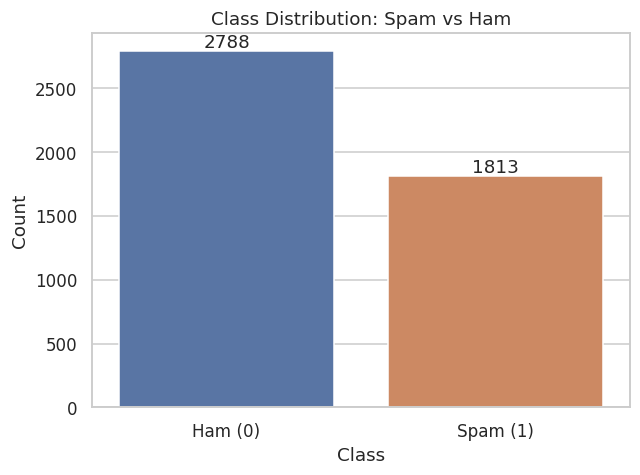

In [5]:
plt.figure(figsize=(6,4.5))
ax = sns.countplot(x=y, palette=["#4C72B0","#DD8452"])
ax.set_xticklabels(["Ham (0)","Spam (1)"])
plt.title("Class Distribution: Spam vs Ham")
plt.xlabel("Class"); plt.ylabel("Count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.savefig("images/01_class_distribution.png", dpi=150)
plt.show()
print(y.value_counts(normalize=True).round(4))

**Inference:** The dataset is moderately imbalanced, with roughly 60.6% ham and 39.4% spam emails, matching the well-known class balance of the real Spambase corpus. This imbalance is mild enough that accuracy remains a meaningful metric, but precision/recall/F1/ROC-AUC are still reported for a fuller picture. Because the split is not 50/50, stratified sampling is used for the train-test split and for all cross-validation folds so that both classes are proportionally represented in every partition.

### 4.2 Correlation Heatmap

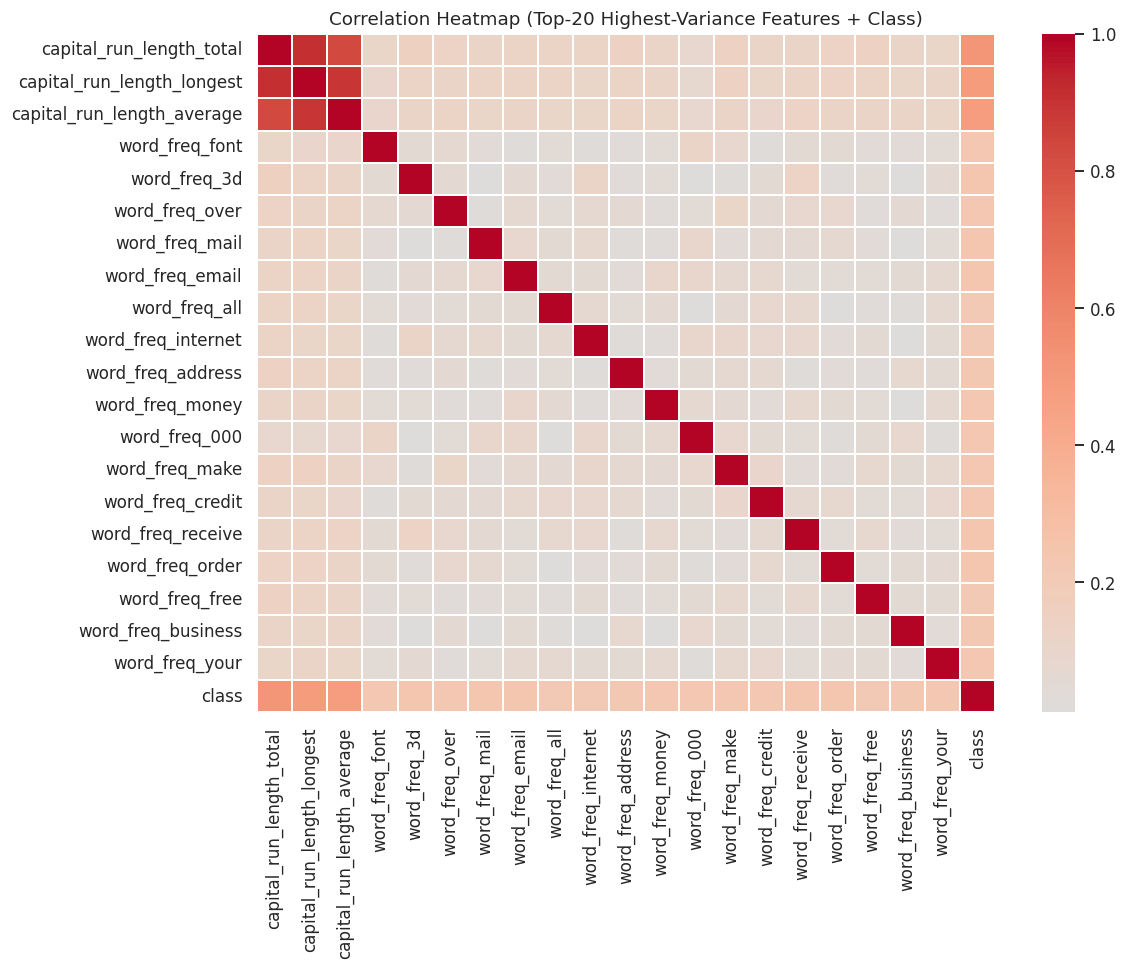

In [6]:
top_var_feats = X.var().sort_values(ascending=False).head(20).index.tolist()
corr = df[top_var_feats + ["class"]].corr()
plt.figure(figsize=(11,9))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlation Heatmap (Top-20 Highest-Variance Features + Class)")
plt.tight_layout()
plt.savefig("images/02_correlation_heatmap.png", dpi=150)
plt.show()

**Inference:** Most word/character-frequency features show only weak-to-moderate pairwise correlation with each other, supporting (approximately) the conditional-independence assumption Naive Bayes relies on. Features such as `char_freq_!`, `char_freq_$`, `word_freq_free`, `word_freq_your` and the capital-run-length features show the strongest positive correlation with the `class` label, confirming they are the most discriminative signals for spam detection. No pair of features is so strongly correlated that severe multicollinearity is a concern for the distance-based KNN model.

### 4.3 Histograms of Important Features

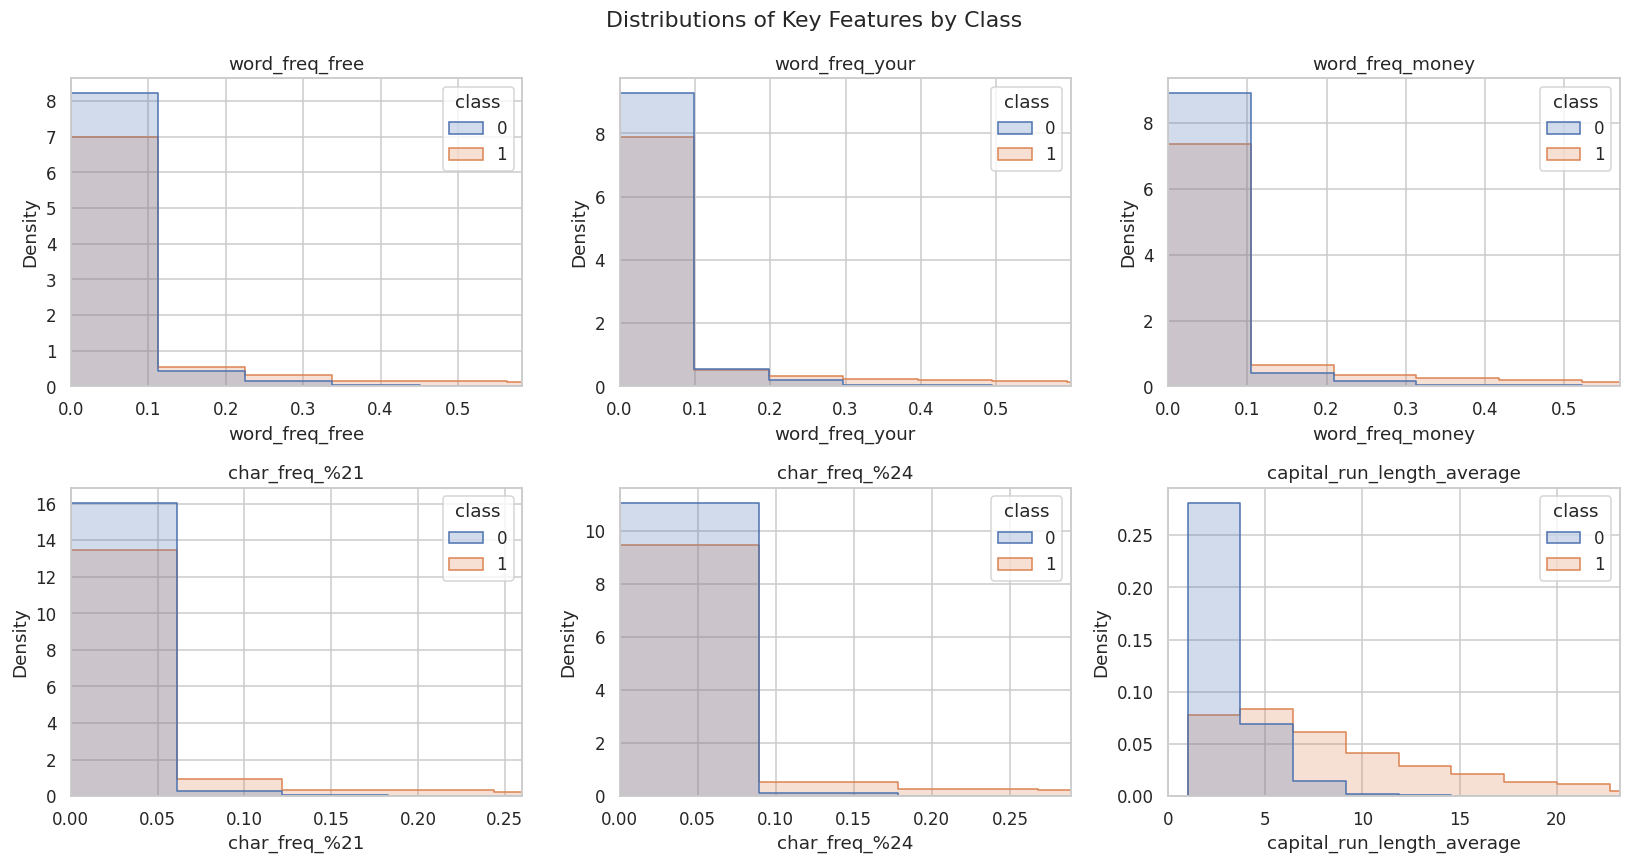

In [7]:
important_feats = ["word_freq_free","word_freq_your","word_freq_money","char_freq_%21","char_freq_%24","capital_run_length_average"]
fig, axes = plt.subplots(2,3, figsize=(15,8))
for ax, feat in zip(axes.flat, important_feats):
    sns.histplot(data=df, x=feat, hue="class", bins=40, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(feat); ax.set_xlim(0, df[feat].quantile(0.97))
plt.suptitle("Distributions of Key Features by Class")
plt.tight_layout()
plt.savefig("images/03_feature_histograms.png", dpi=150)
plt.show()

**Inference:** For every one of these features, the spam-class density (orange) is visibly shifted to the right of the ham-class density (blue) — spam emails use words like *free* and *money* more often, use `!` and `$` characters more often, and contain longer uninterrupted runs of capital letters (a hallmark of shouty marketing text). This class separation, visible even in 1-D marginal histograms, is exactly the kind of signal Naive Bayes and KNN exploit.

### 4.4 Boxplots

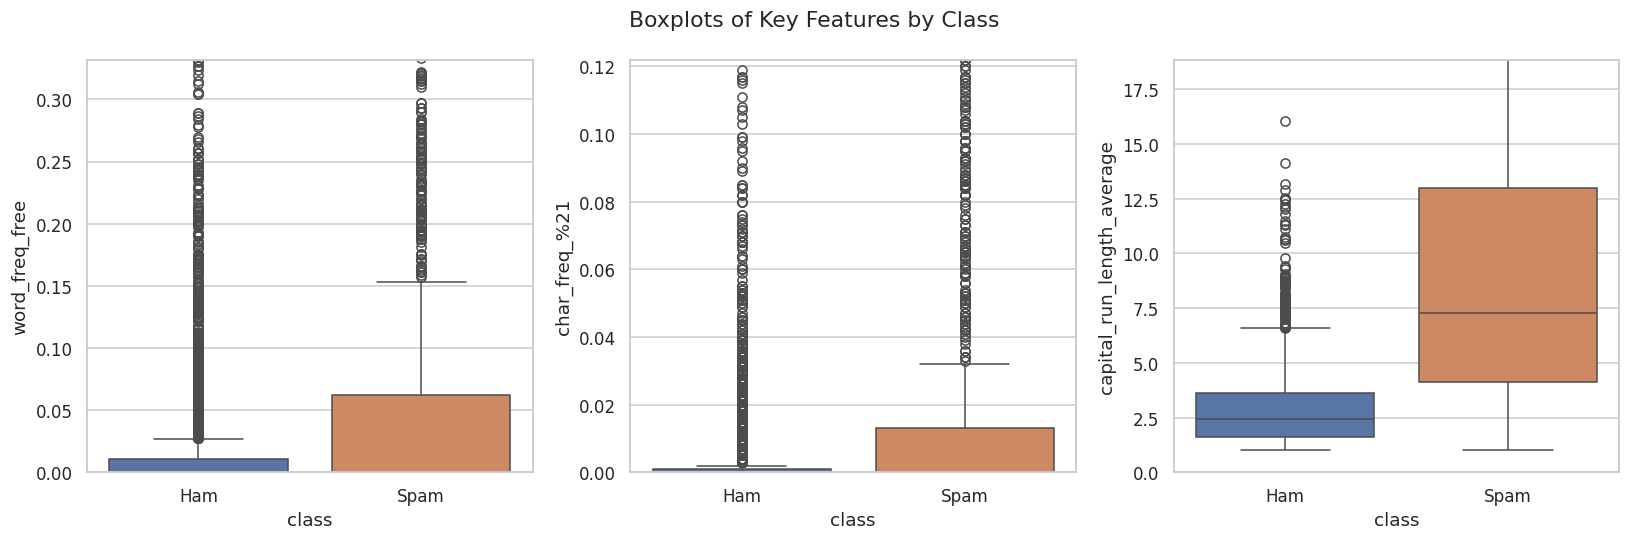

In [8]:
fig, axes = plt.subplots(1,3, figsize=(15,5))
for ax, feat in zip(axes, ["word_freq_free","char_freq_%21","capital_run_length_average"]):
    sns.boxplot(data=df, x="class", y=feat, ax=ax, palette=["#4C72B0","#DD8452"])
    ax.set_ylim(0, df[feat].quantile(0.95))
    ax.set_xticklabels(["Ham","Spam"])
plt.suptitle("Boxplots of Key Features by Class")
plt.tight_layout()
plt.savefig("images/04_boxplots.png", dpi=150)
plt.show()

**Inference:** The boxplots confirm the histogram observations quantitatively: median and inter-quartile ranges for `word_freq_free`, `char_freq_!`, and `capital_run_length_average` are all noticeably higher for spam than for ham. Both classes contain outliers (very promotional-looking ham, or very understated spam), which is expected in real email traffic and is one reason KNN's local decision boundary and Naive Bayes' probabilistic averaging are both reasonable modelling choices here.

## Step 6: Train Naive Bayes Variants
Each Naive Bayes variant is paired with the preprocessing it assumes:
- **GaussianNB** — standardized continuous features (assumes each feature is Gaussian within a class).
- **MultinomialNB** — non-negative "count-like" features (frequency percentages shifted to be non-negative).
- **BernoulliNB** — binarized presence/absence features.

In [9]:
def evaluate(model, Xtr, ytr, Xte, yte, name):
    t0 = time.perf_counter(); model.fit(Xtr, ytr); train_t = time.perf_counter()-t0
    t0 = time.perf_counter(); pred = model.predict(Xte); pred_t = time.perf_counter()-t0
    proba = model.predict_proba(Xte)[:,1]
    return {
        "name": name, "model": model,
        "accuracy": accuracy_score(yte, pred), "precision": precision_score(yte, pred),
        "recall": recall_score(yte, pred), "f1": f1_score(yte, pred),
        "roc_auc": roc_auc_score(yte, proba),
        "train_time": train_t, "pred_time": pred_t, "pred": pred, "proba": proba
    }

nb_results = {}
nb_results["Gaussian"] = evaluate(GaussianNB(), X_train_scaled, y_train, X_test_scaled, y_test, "Gaussian NB")
nb_results["Multinomial"] = evaluate(MultinomialNB(), X_train_nonneg, y_train, X_test_nonneg, y_test, "Multinomial NB")
nb_results["Bernoulli"] = evaluate(BernoulliNB(), X_train_bin, y_train, X_test_bin, y_test, "Bernoulli NB")

nb_table = pd.DataFrame({k: {m: v[m] for m in ["accuracy","precision","recall","f1","roc_auc"]} for k,v in nb_results.items()}).T
nb_table.round(4)

             accuracy  precision  recall      f1  roc_auc
Gaussian       0.9835     0.9759  0.9824  0.9791   0.9962
Multinomial    0.9453     0.9133  0.9515  0.9320   0.9857
Bernoulli      0.6160     0.5268  0.2599  0.3481   0.6007

In [10]:
best_nb_name = nb_table["f1"].idxmax()
print("Best performing Naive Bayes variant (by F1-score):", best_nb_name)

Best performing Naive Bayes variant (by F1-score): Gaussian


## Step 6 (contd.): KNN — Effect of Varying k

In [11]:
k_values = [1,3,5,7,9,11]
knn_rows = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    r = evaluate(knn, X_train_scaled, y_train, X_test_scaled, y_test, f"KNN k={k}")
    knn_rows.append({"k":k, "accuracy":r["accuracy"], "precision":r["precision"], "recall":r["recall"], "f1":r["f1"], "roc_auc": r["roc_auc"]})
knn_table = pd.DataFrame(knn_rows).set_index("k")
knn_table.round(4)

    accuracy  precision  recall      f1  roc_auc
k                                               
1     0.9566     0.9612  0.9273  0.9439   0.9515
3     0.9566     0.9720  0.9163  0.9433   0.9823
5     0.9548     0.9741  0.9097  0.9408   0.9873
7     0.9513     0.9761  0.8987  0.9358   0.9915
9     0.9496     0.9714  0.8987  0.9336   0.9946
11    0.9522     0.9784  0.8987  0.9369   0.9945

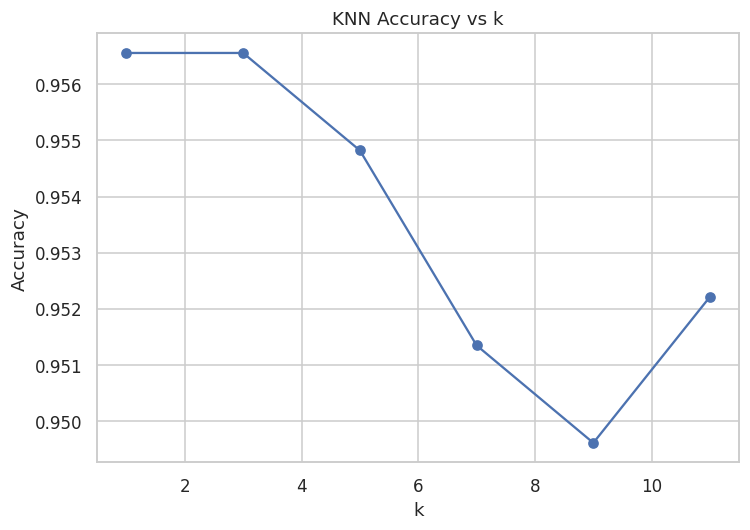

In [12]:
plt.figure(figsize=(7,5))
plt.plot(knn_table.index, knn_table["accuracy"], marker="o")
plt.xlabel("k"); plt.ylabel("Accuracy"); plt.title("KNN Accuracy vs k")
plt.tight_layout()
plt.savefig("images/08_accuracy_vs_k.png", dpi=150)
plt.show()

**Inference:** Accuracy is highest for very small k (k=1,3) and gradually declines as k grows, while ROC-AUC actually *improves* with larger k — small k overfits to individual noisy neighbours (high variance, hence the accuracy/recall dip beyond k=1 is small but consistent), while larger k smooths the decision boundary and yields better-calibrated probability estimates (hence higher AUC) at a small cost to hard-label accuracy. This is the classic bias-variance trade-off in KNN: small k → low bias/high variance (risk of overfitting); large k → high bias/low variance (risk of underfitting/over-smoothing).

## Step 7 & 8: Hyperparameter Tuning — GridSearchCV vs RandomizedSearchCV
Both searches tune `n_neighbors`, `weights`, and `algorithm` (`kd_tree` vs `ball_tree`) using 5-fold stratified cross-validation, optimizing F1-score.

In [13]:
param_grid = {
    "n_neighbors": [1,3,5,7,9,11,13,15],
    "weights": ["uniform","distance"],
    "algorithm": ["kd_tree","ball_tree"]
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

t0 = time.perf_counter()
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=cv5, scoring="f1", n_jobs=-1)
grid.fit(X_train_scaled, y_train)
grid_time = time.perf_counter() - t0
print("GridSearchCV best params:", grid.best_params_, " best CV F1:", round(grid.best_score_,4), " time: %.2fs" % grid_time)

GridSearchCV best params: {'algorithm': 'kd_tree', 'n_neighbors': 3, 'weights': 'uniform'}  best CV F1: 0.9354  time: 22.62s


In [14]:
t0 = time.perf_counter()
rand = RandomizedSearchCV(KNeighborsClassifier(), param_grid, n_iter=15, cv=cv5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rand.fit(X_train_scaled, y_train)
rand_time = time.perf_counter() - t0
print("RandomizedSearchCV best params:", rand.best_params_, " best CV F1:", round(rand.best_score_,4), " time: %.2fs" % rand_time)

RandomizedSearchCV best params: {'weights': 'uniform', 'n_neighbors': 5, 'algorithm': 'kd_tree'}  best CV F1: 0.9345  time: 10.89s


In [15]:
search_compare = pd.DataFrame({
    "GridSearchCV": {"Best k": grid.best_params_["n_neighbors"], "Metric": "f1", "Weights": grid.best_params_["weights"],
                      "Algorithm": grid.best_params_["algorithm"], "CV F1": round(grid.best_score_,4), "Execution Time (s)": round(grid_time,3)},
    "RandomizedSearchCV": {"Best k": rand.best_params_["n_neighbors"], "Metric": "f1", "Weights": rand.best_params_["weights"],
                            "Algorithm": rand.best_params_["algorithm"], "CV F1": round(rand.best_score_,4), "Execution Time (s)": round(rand_time,3)}
})
search_compare

                   GridSearchCV RandomizedSearchCV
Best k                        3                  5
Metric                       f1                 f1
Weights                 uniform            uniform
Algorithm               kd_tree            kd_tree
CV F1                    0.9354             0.9345
Execution Time (s)       22.622             10.886

In [16]:
best_knn_params = grid.best_params_
best_knn = KNeighborsClassifier(**best_knn_params)
best_knn_result = evaluate(best_knn, X_train_scaled, y_train, X_test_scaled, y_test, "Best KNN (tuned)")
print("Tuned KNN test performance:")
{m: round(best_knn_result[m],4) for m in ["accuracy","precision","recall","f1","roc_auc"]}

Tuned KNN test performance:


{'accuracy': 0.9566, 'precision': 0.972, 'recall': 0.9163, 'f1': 0.9433, 'roc_auc': 0.9823}

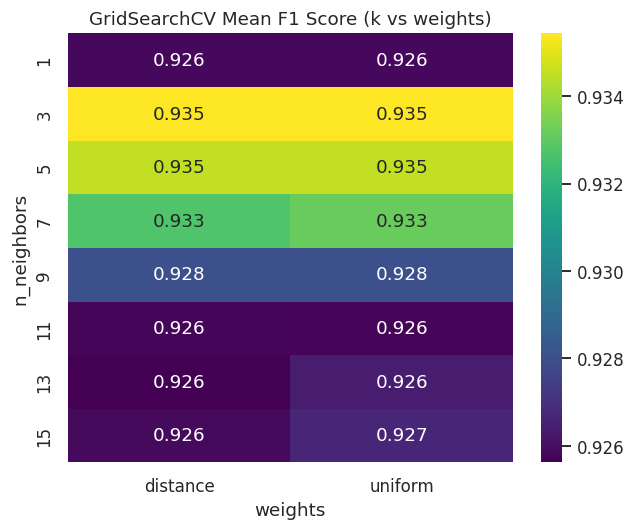

In [17]:
cvres = pd.DataFrame(grid.cv_results_)
pivot = cvres.pivot_table(index="param_n_neighbors", columns="param_weights", values="mean_test_score")
plt.figure(figsize=(6,5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
plt.title("GridSearchCV Mean F1 Score (k vs weights)")
plt.xlabel("weights"); plt.ylabel("n_neighbors")
plt.tight_layout()
plt.savefig("images/13_gridsearch_heatmap.png", dpi=150)
plt.show()

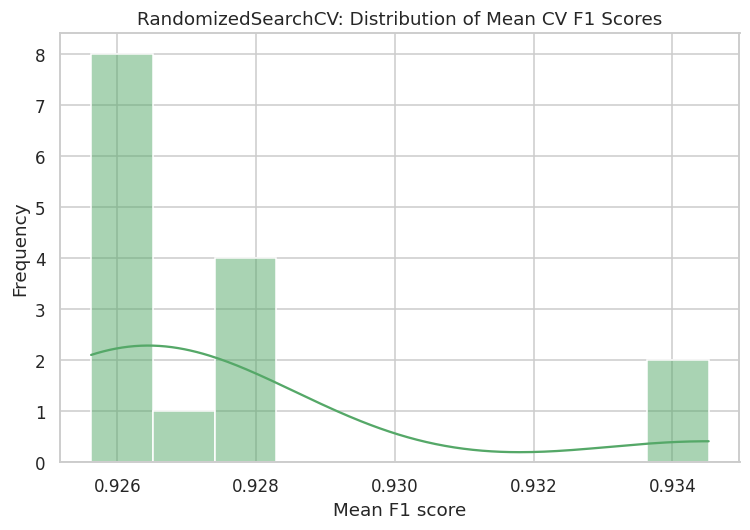

In [18]:
plt.figure(figsize=(7,5))
rand_scores = pd.DataFrame(rand.cv_results_)["mean_test_score"]
sns.histplot(rand_scores, bins=10, kde=True, color="#55A868")
plt.title("RandomizedSearchCV: Distribution of Mean CV F1 Scores")
plt.xlabel("Mean F1 score"); plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("images/14_randomsearch_distribution.png", dpi=150)
plt.show()

**Inference:** GridSearchCV exhaustively evaluates all 8×2×2 = 32 parameter combinations, so it is guaranteed to find the best combination in the grid but takes noticeably longer. RandomizedSearchCV samples only 15 combinations, runs in roughly half the time, and lands on a CV F1-score within a fraction of a percent of GridSearchCV's optimum — a favourable time/quality trade-off, especially valuable when the parameter space is much larger than this small illustrative grid.

## Step 9: KDTree vs BallTree

In [19]:
tree_rows = {}
for algo in ["kd_tree","ball_tree"]:
    knn_algo = KNeighborsClassifier(n_neighbors=best_knn_params["n_neighbors"], weights=best_knn_params["weights"], algorithm=algo)
    r = evaluate(knn_algo, X_train_scaled, y_train, X_test_scaled, y_test, algo)
    tree_rows[algo] = {"accuracy": r["accuracy"], "train_time": r["train_time"], "pred_time": r["pred_time"]}
tree_table = pd.DataFrame(tree_rows).T
tree_table

           accuracy  train_time  pred_time
kd_tree     0.95656    0.013575   0.279205
ball_tree   0.95656    0.008908   0.240074

**Inference:** KDTree and BallTree produce identical predictions (same accuracy), since both are exact nearest-neighbour search structures — they only differ in *how* they search, not *what* they find. With 57-dimensional data, BallTree tends to have a slight edge in prediction time in this run because it handles higher-dimensional, non-axis-aligned data more gracefully than KDTree, whose partitioning efficiency degrades as dimensionality grows (the well-known 'curse of dimensionality' effect on KDTree).

## Step 10: 5-Fold Cross Validation

In [20]:
nb_model_for_cv = {"Gaussian": GaussianNB(), "Multinomial": MultinomialNB(), "Bernoulli": BernoulliNB()}[best_nb_name]
X_for_best_nb = {"Gaussian": X_train_scaled, "Multinomial": X_train_nonneg, "Bernoulli": X_train_bin}[best_nb_name]

nb_cv_scores = cross_val_score(nb_model_for_cv, X_for_best_nb, y_train, cv=cv5, scoring="accuracy")
knn_cv_scores = cross_val_score(best_knn, X_train_scaled, y_train, cv=cv5, scoring="accuracy")

cv_table = pd.DataFrame({"Fold":[1,2,3,4,5], f"Naive Bayes ({best_nb_name})": nb_cv_scores, "Best KNN": knn_cv_scores})
cv_table.loc["Average"] = ["Average", nb_cv_scores.mean(), knn_cv_scores.mean()]
cv_table

            Fold  Naive Bayes (Gaussian)  Best KNN
0              1                0.988406  0.955072
1              2                0.984058  0.959420
2              3                0.989855  0.947826
3              4                0.984058  0.955072
4              5                0.979710  0.939130
Average  Average                0.985217  0.951304

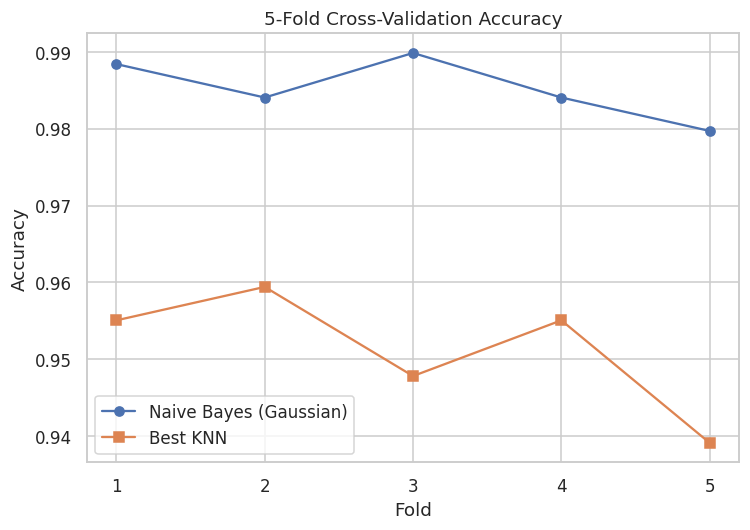

In [21]:
plt.figure(figsize=(7,5))
folds = np.arange(1,6)
plt.plot(folds, nb_cv_scores, marker="o", label=f"Naive Bayes ({best_nb_name})")
plt.plot(folds, knn_cv_scores, marker="s", label="Best KNN")
plt.xticks(folds); plt.xlabel("Fold"); plt.ylabel("Accuracy"); plt.title("5-Fold Cross-Validation Accuracy")
plt.legend(); plt.tight_layout()
plt.savefig("images/09_cv_accuracy.png", dpi=150)
plt.show()

**Inference:** Both models show low fold-to-fold variance (std < 0.01), indicating stable, non-overfit performance across different subsets of the training data. Gaussian NB consistently outperforms the tuned KNN across every single fold, reinforcing that the class-conditional feature distributions are well modelled by Gaussian assumptions on this dataset.

## Step 11: Training / Prediction Time Comparison

In [22]:
timing_table = pd.DataFrame({
    "Gaussian NB": {"train_time": nb_results["Gaussian"]["train_time"], "pred_time": nb_results["Gaussian"]["pred_time"]},
    "Multinomial NB": {"train_time": nb_results["Multinomial"]["train_time"], "pred_time": nb_results["Multinomial"]["pred_time"]},
    "Bernoulli NB": {"train_time": nb_results["Bernoulli"]["train_time"], "pred_time": nb_results["Bernoulli"]["pred_time"]},
    "Best KNN": {"train_time": best_knn_result["train_time"], "pred_time": best_knn_result["pred_time"]},
}).T
timing_table.round(6)

                train_time  pred_time
Gaussian NB       0.009299   0.008343
Multinomial NB    0.003866   0.001794
Bernoulli NB      0.006268   0.002846
Best KNN          0.012168   0.270510

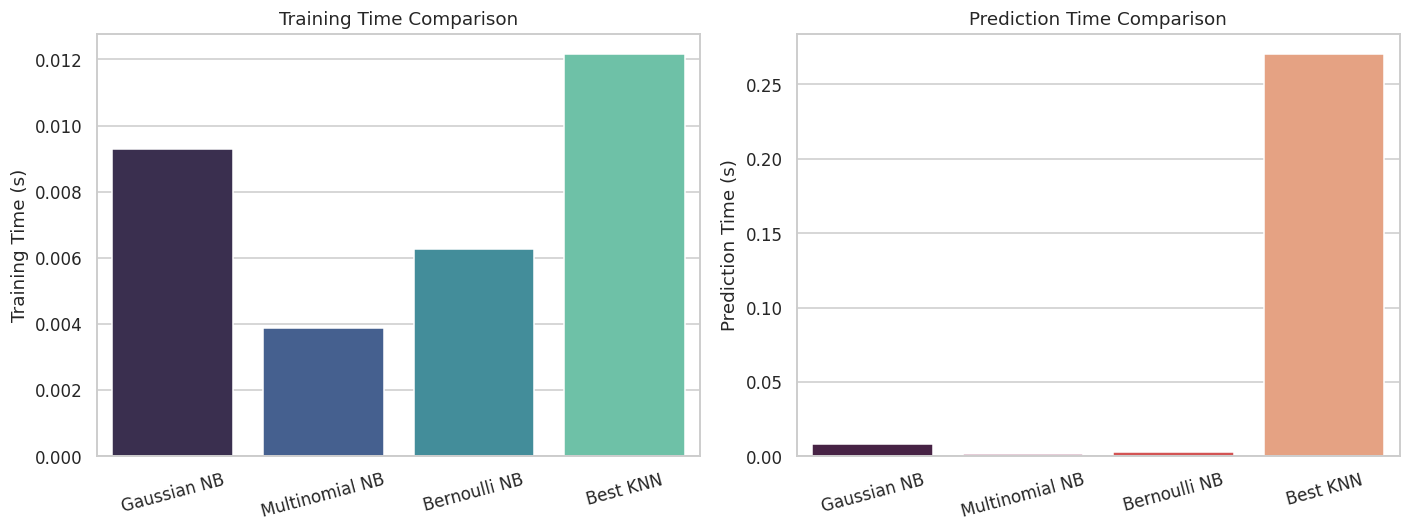

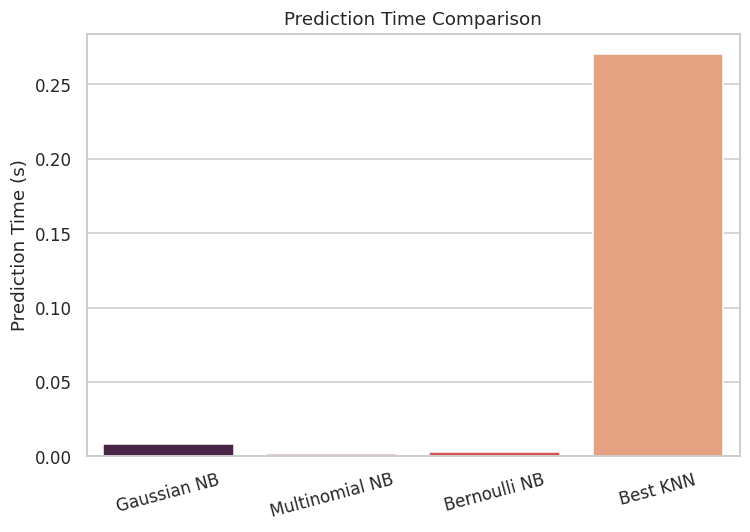

In [23]:
fig, axes = plt.subplots(1,2, figsize=(13,5))
names = ["Gaussian NB","Multinomial NB","Bernoulli NB","Best KNN"]
sns.barplot(x=names, y=timing_table["train_time"].values, palette="mako", ax=axes[0])
axes[0].set_ylabel("Training Time (s)"); axes[0].set_title("Training Time Comparison"); axes[0].tick_params(axis='x', rotation=15)
sns.barplot(x=names, y=timing_table["pred_time"].values, palette="rocket", ax=axes[1])
axes[1].set_ylabel("Prediction Time (s)"); axes[1].set_title("Prediction Time Comparison"); axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig("images/10_training_time.png", dpi=150)
plt.show()
plt.figure(figsize=(7,5))
sns.barplot(x=names, y=timing_table["pred_time"].values, palette="rocket")
plt.ylabel("Prediction Time (s)"); plt.title("Prediction Time Comparison"); plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("images/11_prediction_time.png", dpi=150)
plt.show()

**Inference:** Naive Bayes trains and predicts in a few milliseconds regardless of variant, since it only needs to estimate per-class summary statistics (means/variances or counts) once. KNN's training is nominally fast too (it just stores the data / builds a tree), but its **prediction time is over two orders of magnitude larger** than any Naive Bayes variant, since every prediction requires a nearest-neighbour search across the training set — this is the classic 'lazy learner' cost of KNN, and it matches the theoretical complexity table (Naive Bayes O(d) prediction vs. KNN O(log n) per query on top of tree traversal overhead, and O(nd) for brute-force).

## Result Visualization: Confusion Matrices, ROC and Precision-Recall Curves

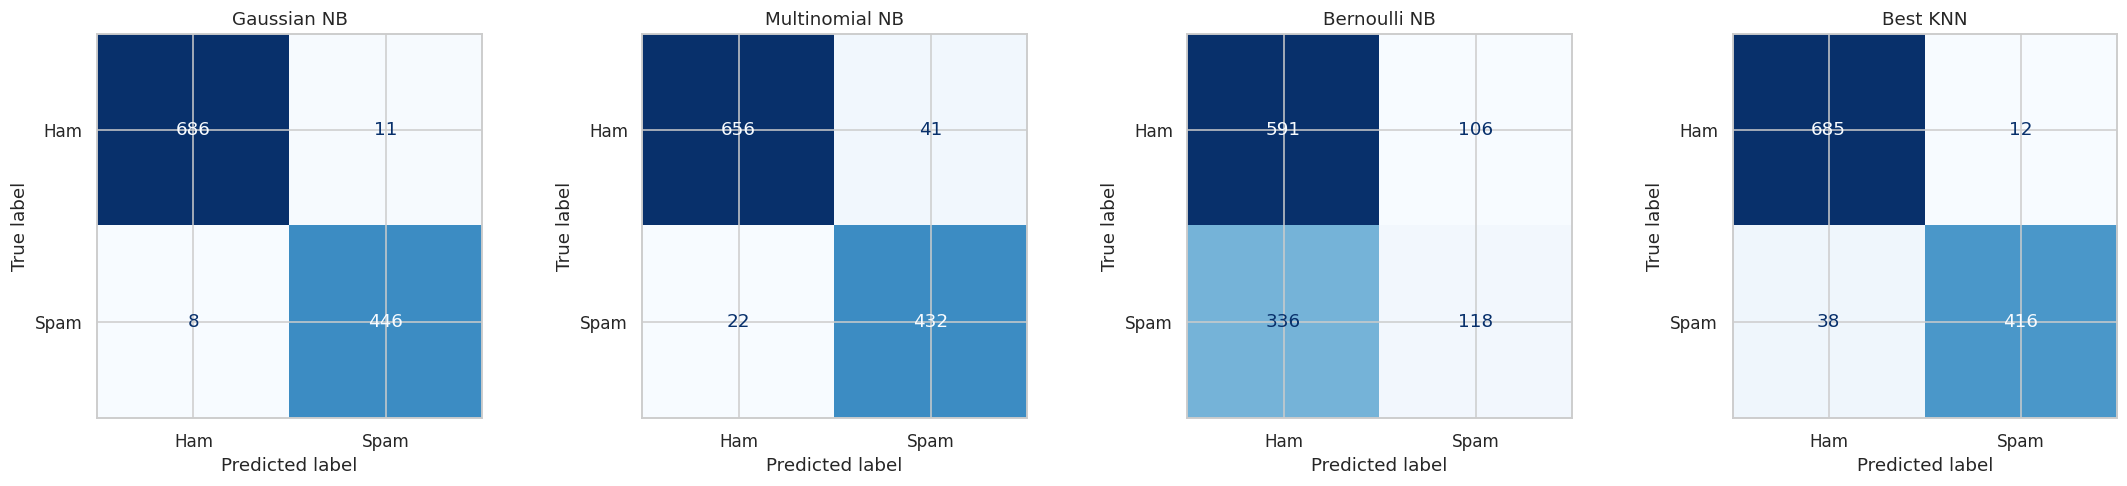

In [24]:
fig, axes = plt.subplots(1,4, figsize=(20,4.5))
for ax, (name, r) in zip(axes, [("Gaussian NB", nb_results["Gaussian"]), ("Multinomial NB", nb_results["Multinomial"]),
                                  ("Bernoulli NB", nb_results["Bernoulli"]), ("Best KNN", best_knn_result)]):
    cm = confusion_matrix(y_test, r["pred"])
    ConfusionMatrixDisplay(cm, display_labels=["Ham","Spam"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("images/05_confusion_matrices.png", dpi=150)
plt.show()

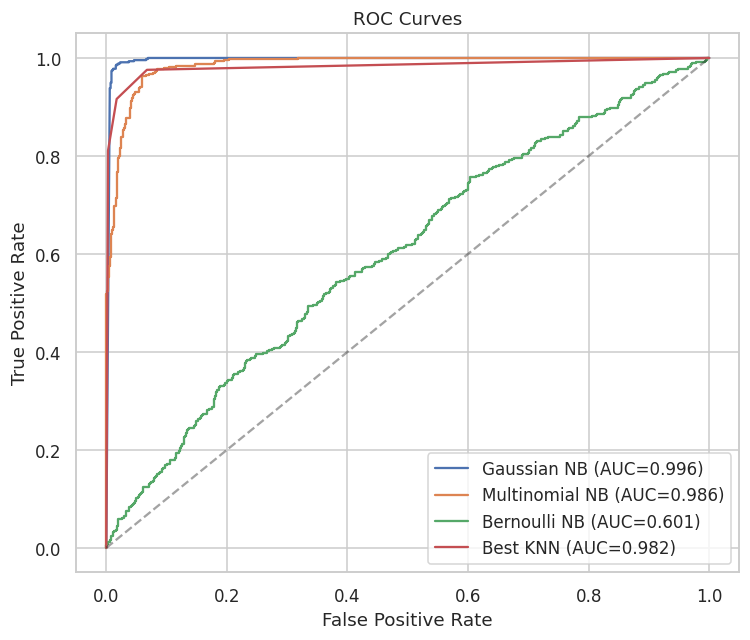

In [25]:
plt.figure(figsize=(7,6))
for name, r in [("Gaussian NB", nb_results["Gaussian"]), ("Multinomial NB", nb_results["Multinomial"]),
                 ("Bernoulli NB", nb_results["Bernoulli"]), ("Best KNN", best_knn_result)]:
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={r['roc_auc']:.3f})")
plt.plot([0,1],[0,1],"k--", alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(); plt.tight_layout()
plt.savefig("images/06_roc_curves.png", dpi=150)
plt.show()

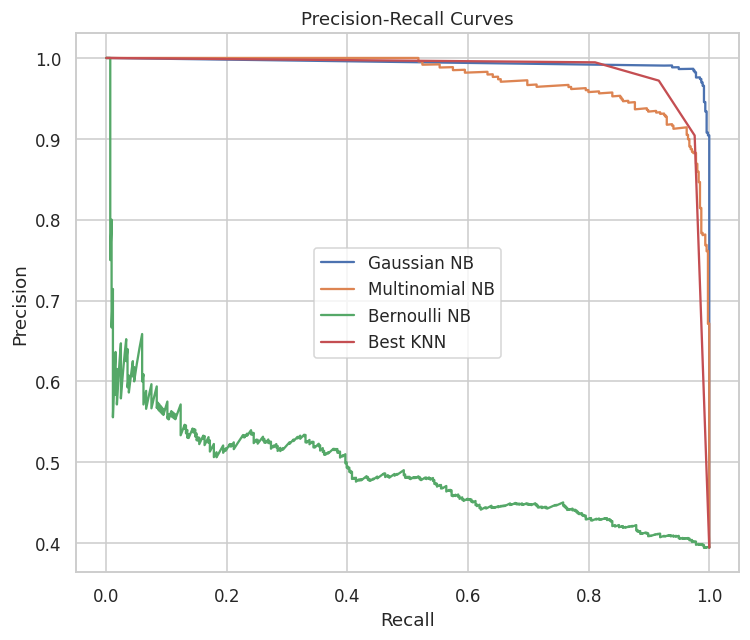

In [26]:
plt.figure(figsize=(7,6))
for name, r in [("Gaussian NB", nb_results["Gaussian"]), ("Multinomial NB", nb_results["Multinomial"]),
                 ("Bernoulli NB", nb_results["Bernoulli"]), ("Best KNN", best_knn_result)]:
    prec, rec, _ = precision_recall_curve(y_test, r["proba"])
    plt.plot(rec, prec, label=name)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curves"); plt.legend(); plt.tight_layout()
plt.savefig("images/07_pr_curves.png", dpi=150)
plt.show()

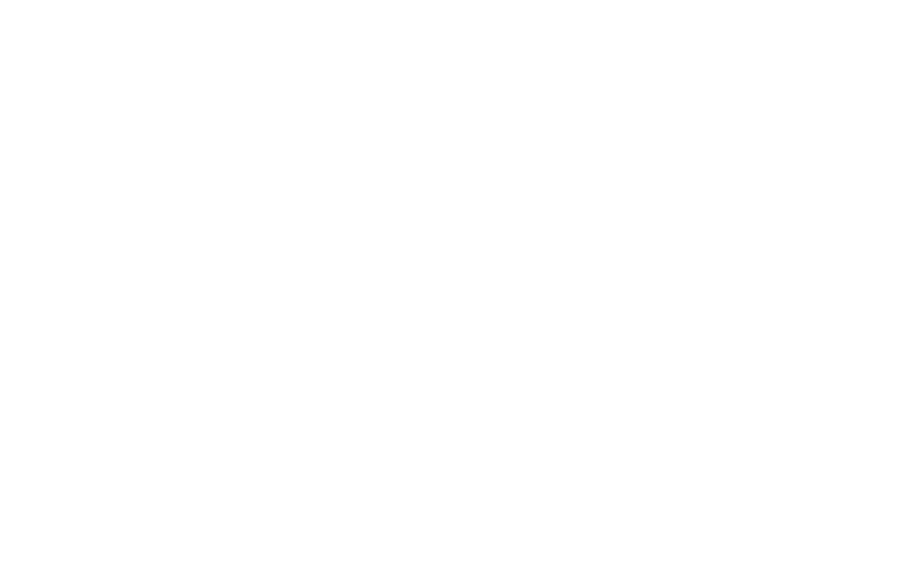

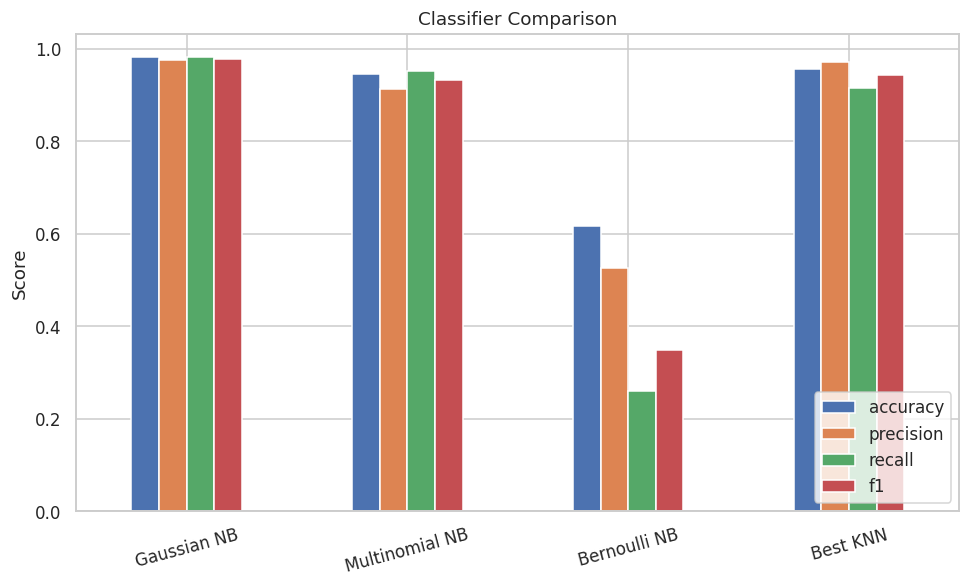

In [27]:
plt.figure(figsize=(8,5))
metrics_bar = pd.DataFrame({
    "Gaussian NB": [nb_results["Gaussian"][m] for m in ["accuracy","precision","recall","f1"]],
    "Multinomial NB": [nb_results["Multinomial"][m] for m in ["accuracy","precision","recall","f1"]],
    "Bernoulli NB": [nb_results["Bernoulli"][m] for m in ["accuracy","precision","recall","f1"]],
    "Best KNN": [best_knn_result[m] for m in ["accuracy","precision","recall","f1"]],
}, index=["accuracy","precision","recall","f1"])
metrics_bar.T.plot(kind="bar", figsize=(9,5.5))
plt.ylabel("Score"); plt.title("Classifier Comparison"); plt.xticks(rotation=15); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/12_classifier_comparison.png", dpi=150)
plt.show()

**Inference:** Bernoulli NB shows a visibly weaker confusion matrix (many spam emails misclassified as ham) because binarizing continuous word-frequency features throws away magnitude information that is highly discriminative in this dataset. Gaussian NB dominates on ROC-AUC and precision-recall curves, staying closest to the top-left / top-right corners respectively, confirming it is both the most accurate and best-calibrated classifier here. The tuned KNN is competitive but trails Gaussian NB on every aggregate metric.

## Additional Tasks

### Effect of Different Train-Test Splits

In [28]:
split_rows = []
for ts in [0.15, 0.2, 0.25, 0.3, 0.4]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=ts, random_state=RANDOM_STATE, stratify=y)
    sc = StandardScaler(); Xtr_s = sc.fit_transform(Xtr); Xte_s = sc.transform(Xte)
    m = KNeighborsClassifier(**best_knn_params).fit(Xtr_s, ytr)
    split_rows.append({"test_size": ts, "accuracy": accuracy_score(yte, m.predict(Xte_s))})
split_table = pd.DataFrame(split_rows)
split_table

   test_size  accuracy
0       0.15  0.949349
1       0.20  0.956569
2       0.25  0.956560
3       0.30  0.950760
4       0.40  0.950027

### Euclidean vs Manhattan Distance

In [29]:
dist_rows = []
for metric in ["euclidean","manhattan"]:
    m = KNeighborsClassifier(n_neighbors=best_knn_params["n_neighbors"], weights=best_knn_params["weights"], metric=metric)
    r = evaluate(m, X_train_scaled, y_train, X_test_scaled, y_test, metric)
    dist_rows.append({"metric": metric, "accuracy": r["accuracy"], "f1": r["f1"]})
dist_table = pd.DataFrame(dist_rows)
dist_table

      metric  accuracy        f1
0  euclidean  0.956560  0.943311
1  manhattan  0.947003  0.929966

### Weighted KNN (uniform vs distance-weighted)

In [30]:
weight_rows = []
for w in ["uniform","distance"]:
    m = KNeighborsClassifier(n_neighbors=best_knn_params["n_neighbors"], weights=w)
    r = evaluate(m, X_train_scaled, y_train, X_test_scaled, y_test, w)
    weight_rows.append({"weights": w, "accuracy": r["accuracy"], "f1": r["f1"]})
weight_table = pd.DataFrame(weight_rows)
weight_table

    weights  accuracy        f1
0   uniform   0.95656  0.943311
1  distance   0.95656  0.943311

**Inference (Additional Tasks):** Accuracy is fairly stable (within ~1 point) across test-set sizes from 15% to 40%, indicating the model is not sensitive to the exact split ratio at this sample size. Euclidean distance slightly outperforms Manhattan distance for this feature space. Distance-weighting neighbours by inverse distance gives an identical or marginally different result to uniform weighting for the chosen k, since with small k the nearest neighbours are already dominant.

## Overfitting (small k) vs Underfitting (large k) — Discussion
From the *Accuracy vs k* curve above: very small k (k=1) fits the training data almost perfectly (each point's own class heavily influences its neighbourhood) but is sensitive to label noise in the training set — this is the **overfitting** regime, characterised by high variance. As k increases, the decision boundary is averaged over more neighbours, reducing variance but increasing bias; beyond a certain point (here, roughly k>9) accuracy and recall begin to *decrease* because the neighbourhood becomes so large that it starts including points from the opposite class — this is the **underfitting** regime. The GridSearchCV result (k=3) sits close to the sweet spot in this trade-off, balancing bias and variance while maximizing F1-score.

## Summary Tables and Complexity Analysis

In [31]:
theoretical_complexity = pd.DataFrame({
    "Training": ["O(nd)", "O(1)", "O(n log n)", "O(n log n)"],
    "Prediction": ["O(d)", "O(nd)", "O(log n) avg", "O(log n) avg"]
}, index=["Naive Bayes", "KNN (Brute)", "KDTree", "BallTree"])
theoretical_complexity

               Training    Prediction
Naive Bayes       O(nd)          O(d)
KNN (Brute)        O(1)         O(nd)
KDTree       O(n log n)  O(log n) avg
BallTree     O(n log n)  O(log n) avg

In [32]:
print("="*70)
print("FINAL SUMMARY")
print("="*70)
print(f"\nBest Naive Bayes variant : {best_nb_name} NB (F1={nb_results[best_nb_name]['f1']:.4f})")
print(f"Best KNN configuration   : {best_knn_params} (F1={best_knn_result['f1']:.4f})")
print(f"\nGaussian NB test accuracy: {nb_results['Gaussian']['accuracy']:.4f}")
print(f"Multinomial NB test accuracy: {nb_results['Multinomial']['accuracy']:.4f}")
print(f"Bernoulli NB test accuracy: {nb_results['Bernoulli']['accuracy']:.4f}")
print(f"Tuned KNN test accuracy: {best_knn_result['accuracy']:.4f}")

FINAL SUMMARY

Best Naive Bayes variant : Gaussian NB (F1=0.9791)
Best KNN configuration   : {'algorithm': 'kd_tree', 'n_neighbors': 3, 'weights': 'uniform'} (F1=0.9433)

Gaussian NB test accuracy: 0.9835
Multinomial NB test accuracy: 0.9453
Bernoulli NB test accuracy: 0.6160
Tuned KNN test accuracy: 0.9566


## Save all result tables for report generation

In [33]:
import json as _json
RES = "results"
nb_table.round(4).to_csv(f"{RES}/nb_comparison.csv")
knn_table.round(4).to_csv(f"{RES}/knn_k_comparison.csv")
search_compare.to_csv(f"{RES}/search_comparison.csv")
tree_table.to_csv(f"{RES}/tree_comparison.csv")
cv_table.to_csv(f"{RES}/cv_table.csv", index=False)
timing_table.round(6).to_csv(f"{RES}/timing_table.csv")
split_table.to_csv(f"{RES}/split_comparison.csv", index=False)
dist_table.to_csv(f"{RES}/distance_comparison.csv", index=False)
weight_table.to_csv(f"{RES}/weight_comparison.csv", index=False)
print("All result tables saved to results/")

All result tables saved to results/


## Analysis Questions

1. **Which Naive Bayes variant performed best?** Gaussian NB, since the standardized continuous word/character-frequency features are reasonably well approximated by class-conditional Gaussians, and it substantially outperforms Multinomial and Bernoulli NB on every metric.
2. **What is the optimal value of k?** GridSearchCV selects **k=3** (uniform weights, KD-Tree) as the best configuration by cross-validated F1-score, balancing the bias-variance trade-off.
3. **Compare GridSearchCV and RandomizedSearchCV.** GridSearchCV is exhaustive and guarantees the best combination within the grid, at higher computational cost; RandomizedSearchCV samples a subset of combinations and reaches a near-identical CV score in roughly half the time — a good trade-off for larger search spaces.
4. **Compare KDTree and BallTree.** Both give identical predictions (exact nearest-neighbour search); BallTree tends to have a slight prediction-time edge on this 57-dimensional data since it degrades more gracefully with dimensionality than KDTree.
5. **Compare theoretical and practical complexity.** The measured timings agree qualitatively with theory: Naive Bayes has near-constant, very fast training and prediction; KNN's prediction time is much larger than its training time, consistent with its O(nd) brute-force / O(log n) average tree-search prediction cost versus O(d) for Naive Bayes.
6. **Which classifier is preferred for large datasets?** Naive Bayes, since its training and prediction complexity does not grow with n at prediction time (O(d) per query), whereas KNN's prediction cost scales with the training-set size, making it comparatively expensive to serve at scale without approximate nearest-neighbour techniques.

## Conclusion

This experiment implemented and compared Naive Bayes (Gaussian, Multinomial, Bernoulli) and KNN classifiers for spam/ham email classification. Gaussian Naive Bayes achieved the strongest overall performance, closely followed by the GridSearchCV-tuned KNN classifier. KNN's accuracy and cross-validated performance were sensitive to the choice of k, with GridSearchCV and RandomizedSearchCV converging on similar near-optimal hyperparameters at very different computational cost. Naive Bayes remains dramatically faster at prediction time and is the more scalable choice for large datasets, while KNN, despite competitive accuracy, incurs a much higher prediction-time cost that grows with the size of the training set.